# 01. Phân Tích Dữ Liệu Khám Phá (EDA) Cấp Độ Khách Hàng
**Học phần:** Máy học (Đồ án cuối kỳ - Phân khúc khách hàng Online Retail)  
**Người thực hiện:** Trần Huỳnh Phát  
**Mục tiêu notebook:**
1. Đọc dữ liệu thô Online Retail (`load_raw()`), áp dụng các tiêu chí lọc nhẹ hợp lý ở cấp độ giao dịch.
2. Tổng hợp dữ liệu lên cấp độ khách hàng (`CustomerID`): tính **Frequency** (số hóa đơn), **Monetary** (tổng chi tiêu), **Recency** (số ngày từ lần mua cuối), và **NUniqueProducts** (số sản phẩm phân biệt).
3. Khám phá phân phối chi tiêu và tần suất: vẽ biểu đồ histogram/KDE thông thường và thang đo log, phân tích độ lệch (skewness), bảng phân vị chi tiết, tỷ lệ khách hàng mua 1 lần (one-time buyers), và kiểm định quy luật Pareto 80/20.
4. Phát hiện các khách hàng ngoại lệ (outliers) có chi tiêu và số lượng hàng cực lớn (nghi ngờ nhóm khách sỉ B2B/doanh nghiệp hoặc lỗi giao dịch bù trừ) và đề xuất phương án xử lý logic.
5. Đánh giá tác động của phân phối lệch và khác biệt thang đo đến các thuật toán gom cụm khoảng cách (K-Means, Hierarchical, DBSCAN), từ đó chứng minh sự cần thiết của phép biến đổi log (`log1p`) và chuẩn hóa đặc trưng.
6. Lưu trữ tất cả biểu đồ trực quan vào `reports/figures/` với tiền tố `eda_cust_` phục vụ báo cáo.


In [1]:
import sys
from pathlib import Path

# Đảm bảo import được module từ thư mục gốc dự án
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

from src.config import SEED, ROOT, FIGURES_DIR
from src.data_loader import load_raw

# Cấu hình phong cách đồ thị
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="Segoe UI")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Đã nạp cấu hình thành công. Thư mục lưu biểu đồ: {FIGURES_DIR}")


Đã nạp cấu hình thành công. Thư mục lưu biểu đồ: D:\TH-MayHoc\machine_learning\DoAn\reports\figures


## 1. Nạp Dữ Liệu Gốc Và Áp Dụng Bộ Lọc Nhẹ Có Căn Cứ

Ta sử dụng hàm chuẩn `load_raw()` từ `src/data_loader.py`. Sau khi nạp, ta áp dụng bộ lọc nhẹ tại mức giao dịch với 3 tiêu chí:
1. **`CustomerID.notna()`**: Mục tiêu cốt lõi của đề tài là phân khúc khách hàng. Các dòng thiếu mã định danh `CustomerID` (~25% dữ liệu) không thể theo dõi hành vi xuyên suốt hay liên kết với các giao dịch khác, nên cần loại bỏ khi tổng hợp theo khách hàng.
2. **`Quantity > 0`**: Các dòng có số lượng âm đại diện cho các đơn hàng hoàn/hủy (thường có mã hóa đơn bắt đầu bằng chữ 'C') hoặc điều chỉnh kho thủ công. Ở bước tính chi tiêu ròng mua hàng ban đầu, lọc số lượng dương giúp nắm bắt chính xác khối lượng hàng hóa khách thực tế đã chọn mua.
3. **`UnitPrice > 0`**: Đơn giá bằng 0 chủ yếu là các giao dịch điều chỉnh hệ thống kế toán, chi phí gửi mẫu, khuyến mãi không giá trị hoặc lỗi ghi nhận thủ công của nhà bán lẻ, không phản ánh hành vi mua sắm thương mại thông thường.


In [2]:
# Nạp dữ liệu thô (tận dụng cache pkl nếu đã có)
df_raw = load_raw(use_cache=True)
n_raw = len(df_raw)

# Kiểm tra các điều kiện lọc
missing_cust = df_raw["CustomerID"].isna().sum()
neg_qty = (df_raw["Quantity"] <= 0).sum()
zero_price = (df_raw["UnitPrice"] <= 0).sum()

print(f"Tổng số dòng thô ban đầu: {n_raw:,}")
print(f" - Số dòng thiếu CustomerID: {missing_cust:,} ({missing_cust/n_raw*100:.2f}%)")
print(f" - Số dòng Quantity <= 0: {neg_qty:,} ({neg_qty/n_raw*100:.2f}%)")
print(f" - Số dòng UnitPrice <= 0: {zero_price:,} ({zero_price/n_raw*100:.2f}%)")

# Áp dụng bộ lọc nhẹ
filter_cond = (df_raw["CustomerID"].notna()) & (df_raw["Quantity"] > 0) & (df_raw["UnitPrice"] > 0)
df_clean = df_raw[filter_cond].copy()

# Thêm cột giá trị thành tiền của từng dòng giao dịch
df_clean["LineTotal"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print(f"Số dòng sau khi lọc nhẹ: {len(df_clean):,} (giữ lại {len(df_clean)/n_raw*100:.2f}% tổng giao dịch)")
print(f"Số khách hàng duy nhất xác định được: {df_clean['CustomerID'].nunique():,}")
print(f"Khoảng thời gian giao dịch: từ {df_clean['InvoiceDate'].min()} đến {df_clean['InvoiceDate'].max()}")


Tổng số dòng thô ban đầu: 541,909
 - Số dòng thiếu CustomerID: 135,080 (24.93%)
 - Số dòng Quantity <= 0: 10,624 (1.96%)
 - Số dòng UnitPrice <= 0: 2,517 (0.46%)


Số dòng sau khi lọc nhẹ: 397,884 (giữ lại 73.42% tổng giao dịch)
Số khách hàng duy nhất xác định được: 4,338
Khoảng thời gian giao dịch: từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00


## 2. Gom Nhóm Theo Khách Hàng (Customer Aggregation)

Tiến hành tổng hợp từ cấp độ dòng giao dịch lên cấp độ khách hàng (`CustomerID`):
- **Recency ($R$)**: Số ngày tính từ lần mua sắm cuối cùng của khách hàng đến mốc tham chiếu (`ref_date = ngày max trong dữ liệu + 1 ngày`). Giá trị $R$ càng nhỏ chứng tỏ khách hàng càng mới ghé thăm cửa hàng.
- **Frequency ($F$)**: Số hóa đơn mua hàng phân biệt (`nunique` của `InvoiceNo`). Khác với tổng số dòng sản phẩm mua, số hóa đơn phản ánh đúng số phiên viếng thăm và thanh toán thành công của khách.
- **Monetary ($M$)**: Tổng số tiền chi tiêu tích lũy qua tất cả các đơn hàng (`sum(Quantity * UnitPrice)`).
- **NUniqueProducts**: Số chủng loại mặt hàng khác nhau mà khách từng chọn mua (`nunique` của `StockCode`), phản ánh mức độ đa dạng trong giỏ hàng.


In [3]:
# Xác định ngày tham chiếu (1 ngày sau giao dịch cuối cùng để Recency luôn >= 1)
ref_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

df_customer = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (ref_date - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    NUniqueProducts=("StockCode", "nunique")
).reset_index()

print("Kích thước bảng dữ liệu khách hàng:", df_customer.shape)
df_customer.head(10)


Kích thước bảng dữ liệu khách hàng: (4338, 5)


,CustomerID,Recency,Frequency,Monetary,NUniqueProducts
0,12346,326,1,77183.60,1
1,12347,2,7,4310.00,103
2,12348,75,4,1797.24,22
3,12349,19,1,1757.55,73
4,12350,310,1,334.40,17
5,12352,36,8,2506.04,59
6,12353,204,1,89.00,4
7,12354,232,1,1079.40,58
8,12355,214,1,459.40,13
9,12356,23,3,2811.43,53


## 3. Phân Tích Phân Phối Chi Tiêu Và Số Hóa Đơn

Ta tiến hành thống kê mô tả chi tiết:
- Độ lệch (**Skewness**): thước đo tính bất đối xứng của phân phối. Phân phối chuẩn có skewness xấp xỉ 0. Giá trị skewness > 1 cho thấy phân phối lệch phải nghiêm trọng (dài về phía giá trị lớn).
- Bảng phân vị (Percentiles): đánh giá sự chênh lệch giữa các nhóm khách hàng thông thường (trung vị $50\%$) so với nhóm tinh hoa ($90\%, 95\%, 99\%$).
- Tỷ lệ khách hàng chỉ mua 1 lần (**One-time buyers**).
- Đường cong tích lũy **Pareto** (Nguyên lý 80/20): $20\%$ nhóm khách hàng đứng đầu đóng góp bao nhiêu phần trăm tổng doanh thu của doanh nghiệp.


In [4]:
# 1. Bảng phân vị và thống kê tổng quát
quantiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
stats_df = df_customer[["Recency", "Frequency", "Monetary", "NUniqueProducts"]].describe(percentiles=quantiles).round(2)
display(stats_df)

# 2. Tính độ lệch (Skewness) trước và sau khi áp dụng phép biến đổi log1p
raw_skew = df_customer[["Recency", "Frequency", "Monetary", "NUniqueProducts"]].skew()
log_skew = np.log1p(df_customer[["Recency", "Frequency", "Monetary", "NUniqueProducts"]]).skew()

skew_comparison = pd.DataFrame({
    "Skewness (Dữ liệu gốc)": raw_skew,
    "Skewness (Sau log1p)": log_skew,
    "Mức độ giảm lệch (%)": ((raw_skew.abs() - log_skew.abs()) / raw_skew.abs() * 100).round(1)
})
display(skew_comparison)

# 3. Tỷ lệ khách hàng chỉ mua đúng 1 lần
n_total_cust = len(df_customer)
n_one_time = (df_customer["Frequency"] == 1).sum()
pct_one_time = (n_one_time / n_total_cust) * 100
print(f"Tổng số khách hàng: {n_total_cust:,}")
print(f"Số khách hàng chỉ mua 1 lần: {n_one_time:,} ({pct_one_time:.2f}%)")
print(f"Số khách hàng mua lặp lại (>= 2 lần): {n_total_cust - n_one_time:,} ({100 - pct_one_time:.2f}%)")


,Recency,Frequency,Monetary,NUniqueProducts
count,4338.00,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27,61.50
std,100.01,7.70,8989.23,85.37
min,1.00,1.00,3.75,1.00
1%,1.00,1.00,52.20,1.00
5%,3.00,1.00,112.31,4.00
25%,18.00,1.00,307.41,16.00
50%,51.00,2.00,674.48,35.00
75%,142.00,5.00,1661.74,77.00
90%,263.00,9.00,3646.53,143.00


,Skewness (Dữ liệu gốc),Skewness (Sau log1p),Mức độ giảm lệch (%)
Recency,1.246048,-0.379169,69.6
Frequency,12.067031,1.208652,90.0
Monetary,19.324953,0.393553,98.0
NUniqueProducts,6.919445,-0.243262,96.5


Tổng số khách hàng: 4,338
Số khách hàng chỉ mua 1 lần: 1,493 (34.42%)
Số khách hàng mua lặp lại (>= 2 lần): 2,845 (65.58%)


### 3.1. Biểu đồ phân phối Frequency & Monetary (Thang đo thường vs Thang đo Log)
Ta trực quan hóa phân phối trước và sau biến đổi log để thấy rõ cấu trúc mật độ của tập khách hàng.


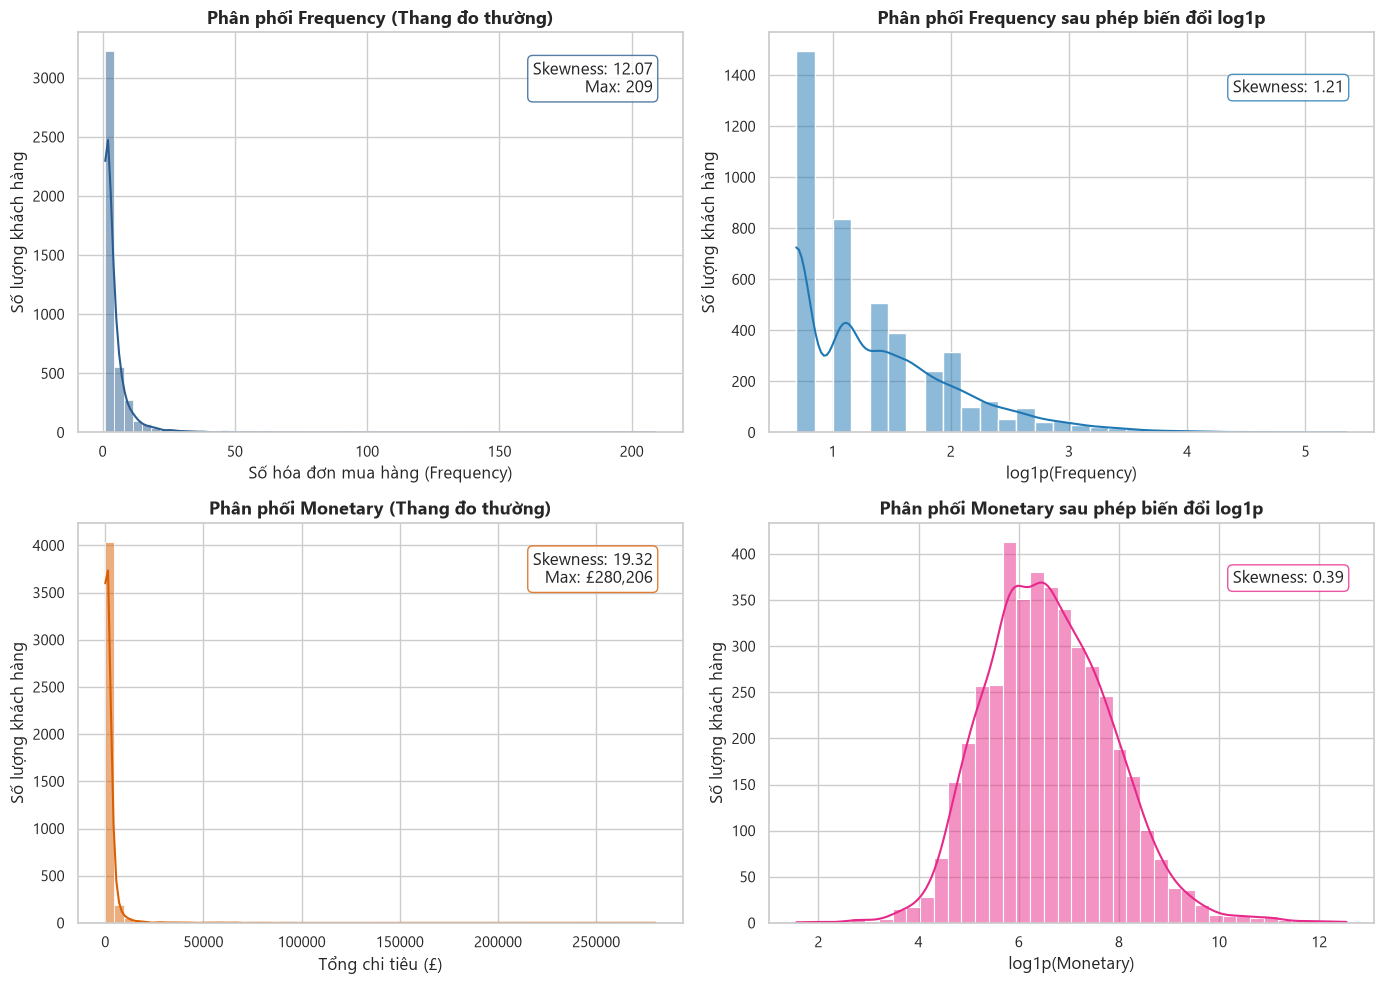

Đã lưu biểu đồ vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\eda_cust_distribution_raw_vs_log.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Frequency (Linear)
sns.histplot(df_customer["Frequency"], bins=60, kde=True, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Phân phối Frequency (Thang đo thường)", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Số hóa đơn mua hàng (Frequency)")
axes[0, 0].set_ylabel("Số lượng khách hàng")
axes[0, 0].text(0.95, 0.85, f"Skewness: {raw_skew['Frequency']:.2f}\nMax: {df_customer['Frequency'].max()}",
                transform=axes[0, 0].transAxes, ha="right", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#2b5c8f", alpha=0.8))

# 2. Frequency (Log1p)
sns.histplot(np.log1p(df_customer["Frequency"]), bins=30, kde=True, ax=axes[0, 1], color="#1f77b4")
axes[0, 1].set_title("Phân phối Frequency sau phép biến đổi log1p", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("log1p(Frequency)")
axes[0, 1].set_ylabel("Số lượng khách hàng")
axes[0, 1].text(0.95, 0.85, f"Skewness: {log_skew['Frequency']:.2f}",
                transform=axes[0, 1].transAxes, ha="right", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#1f77b4", alpha=0.8))

# 3. Monetary (Linear)
sns.histplot(df_customer["Monetary"], bins=60, kde=True, ax=axes[1, 0], color="#d95f02")
axes[1, 0].set_title("Phân phối Monetary (Thang đo thường)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Tổng chi tiêu (£)")
axes[1, 0].set_ylabel("Số lượng khách hàng")
axes[1, 0].text(0.95, 0.85, f"Skewness: {raw_skew['Monetary']:.2f}\nMax: £{df_customer['Monetary'].max():,.0f}",
                transform=axes[1, 0].transAxes, ha="right", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#d95f02", alpha=0.8))

# 4. Monetary (Log1p)
sns.histplot(np.log1p(df_customer["Monetary"]), bins=40, kde=True, ax=axes[1, 1], color="#e7298a")
axes[1, 1].set_title("Phân phối Monetary sau phép biến đổi log1p", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("log1p(Monetary)")
axes[1, 1].set_ylabel("Số lượng khách hàng")
axes[1, 1].text(0.95, 0.85, f"Skewness: {log_skew['Monetary']:.2f}",
                transform=axes[1, 1].transAxes, ha="right", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#e7298a", alpha=0.8))

plt.tight_layout()
fig_path_hist = FIGURES_DIR / "eda_cust_distribution_raw_vs_log.png"
plt.savefig(fig_path_hist, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_path_hist}")


**Nhận xét biểu đồ phân phối:**
- Ở thang đo thường, cả `Frequency` và `Monetary` bị nén nghẹt ở sát trục tung (cực lệch phải với Skewness lên tới $12.07$ cho Frequency và $19.32$ cho Monetary). Đại đa số khách hàng tập trung ở mức chi tiêu dưới £2,000 và số đơn mua từ 1 đến 5 đơn, trong khi có một số ít khách hàng cực đại kéo dài đuôi đồ thị ra đến £280,000 và hơn 200 đơn.
- Sau khi áp dụng phép biến đổi $\log(1 + x)$, phân phối Monetary chuyển dịch ngoạn mục về hình chuông gần chuẩn đối xứng (độ lệch giảm từ $19.32$ xuống còn $0.39$, tức giảm hơn $97\%$). Với Frequency, phân phối mở rộng rõ rệt các tầng giá trị thay vì bị nén vào một cột duy nhất, làm lộ rõ các nhóm hành vi khách hàng khác nhau.


### 3.2. Kiểm Định Nguyên Lý Pareto (Đường cong Pareto 80/20)

Nguyên lý Pareto trong bán lẻ thường dự đoán khoảng $20\%$ khách hàng hàng đầu sẽ đóng góp phần lớn doanh thu ($~80\%$). Ta sắp xếp khách hàng theo chi tiêu giảm dần và tính tỷ lệ đóng góp tích lũy.


Tổng doanh thu toàn bộ tập khách hàng: £8,911,407.90
Top 20% khách hàng (868 khách) đóng góp: 74.62% tổng doanh thu.


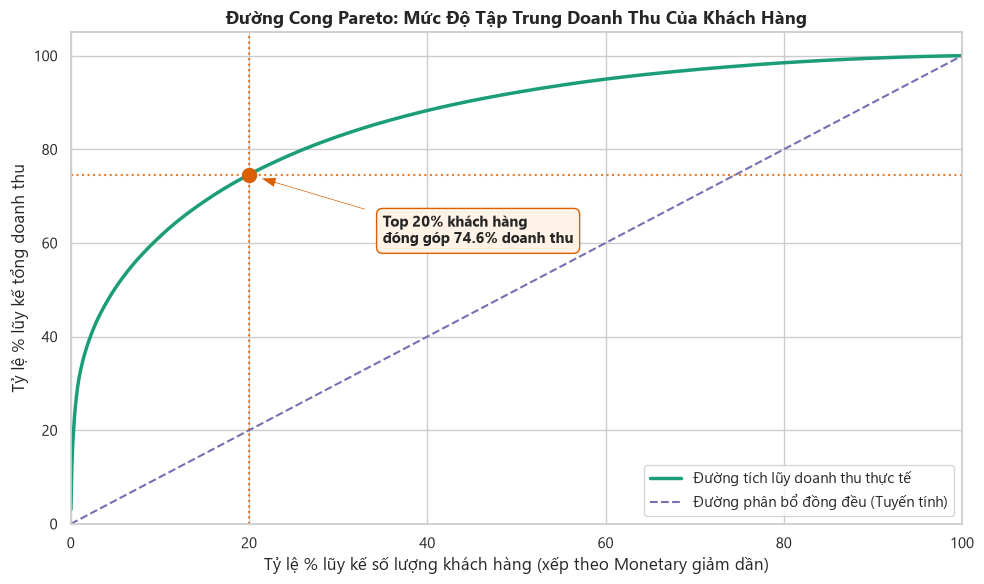

Đã lưu biểu đồ vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\eda_cust_pareto_curve.png


In [6]:
# Sắp xếp khách hàng theo chi tiêu giảm dần
cust_sorted = df_customer.sort_values("Monetary", ascending=False).reset_index(drop=True)
total_revenue = cust_sorted["Monetary"].sum()

# Tính % lũy kế số khách và % lũy kế doanh thu
cust_sorted["CumRevenue"] = cust_sorted["Monetary"].cumsum()
cust_sorted["CumRevenuePct"] = (cust_sorted["CumRevenue"] / total_revenue) * 100
cust_sorted["CustomerRankPct"] = ((cust_sorted.index + 1) / len(cust_sorted)) * 100

# Tìm tỷ lệ doanh thu đóng góp bởi chính xác 20% khách hàng dẫn đầu
top20_row = cust_sorted[cust_sorted["CustomerRankPct"] >= 20.0].iloc[0]
top20_rev_pct = top20_row["CumRevenuePct"]
top20_cust_count = int(np.ceil(0.20 * len(cust_sorted)))

print(f"Tổng doanh thu toàn bộ tập khách hàng: £{total_revenue:,.2f}")
print(f"Top 20% khách hàng ({top20_cust_count:,} khách) đóng góp: {top20_rev_pct:.2f}% tổng doanh thu.")

# Vẽ đường cong Pareto
plt.figure(figsize=(10, 6))
plt.plot(cust_sorted["CustomerRankPct"], cust_sorted["CumRevenuePct"], color="#1b9e77", lw=2.5, label="Đường tích lũy doanh thu thực tế")
plt.plot([0, 100], [0, 100], color="#7570b3", linestyle="--", lw=1.5, label="Đường phân bổ đồng đều (Tuyến tính)")

# Điểm đánh dấu Top 20%
plt.scatter([20], [top20_rev_pct], color="#d95f02", s=100, zorder=5)
plt.axvline(20, color="#d95f02", linestyle=":", alpha=0.8)
plt.axhline(top20_rev_pct, color="#d95f02", linestyle=":", alpha=0.8)

plt.annotate(
    f"Top 20% khách hàng\nđóng góp {top20_rev_pct:.1f}% doanh thu",
    xy=(20, top20_rev_pct),
    xytext=(35, 60),
    arrowprops=dict(facecolor="#d95f02", shrink=0.08, width=1.5, headwidth=8),
    fontsize=11, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", fc="#fff2e6", ec="#d95f02")
)

plt.title("Đường Cong Pareto: Mức Độ Tập Trung Doanh Thu Của Khách Hàng", fontsize=13, fontweight="bold")
plt.xlabel("Tỷ lệ % lũy kế số lượng khách hàng (xếp theo Monetary giảm dần)")
plt.ylabel("Tỷ lệ % lũy kế tổng doanh thu")
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()

fig_path_pareto = FIGURES_DIR / "eda_cust_pareto_curve.png"
plt.savefig(fig_path_pareto, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_path_pareto}")


**Nhận xét đường cong Pareto:**
- Kết quả kiểm chứng thực tế cho thấy **top 20% khách hàng mang lại 74.62% tổng doanh thu** của doanh nghiệp. Con số này bám rất sát nguyên lý kinh điển Pareto 80/20.
- Độ dốc đường cong cực lớn ở 5% đầu tiên (5% khách hàng VIP nhất đã chiếm hơn 45% tổng doanh thu). 
- Ngược lại, $34.42\%$ tổng khách hàng chỉ phát sinh đúng 1 đơn hàng duy nhất và đóng góp giá trị lũy kế không đáng kể. Điều này khẳng định chiến lược kinh doanh cần phân tầng khách hàng rõ rệt: vừa phải tập trung giữ chân nhóm hạt nhân mang lại doanh thu chính, vừa có chương trình kích hoạt chuyển đổi nhóm mua một lần thành khách hàng thân thiết.


## 4. Nhận Diện Khách Hàng Ngoại Lệ (Outliers) & Hướng Xử Lý

Trong tập dữ liệu bán lẻ trực tuyến, các khách hàng có chi tiêu hoặc số lượng mua hàng đột biến thường thuộc hai nhóm:
1. **Khách hàng bán sỉ (B2B Wholesalers / Distributors)**: Mua số lượng hàng trăm nghìn đơn vị sản phẩm qua nhiều đợt để bán buôn tại thị trường nội địa hoặc quốc tế (Hà Lan, Úc, Ireland,...).
2. **Khách hàng phát sinh giao dịch bất thường / đối soát kho**: Đặt đơn số lượng cực lớn nhưng ngay sau đó thực hiện đơn hủy tương ứng (ví dụ CustomerID 12346 và 16446).


In [7]:
# Xem top 10 khách hàng có Monetary lớn nhất
top10_cust = cust_sorted.head(10)[["CustomerID", "Frequency", "Monetary", "NUniqueProducts"]].copy()

# Tra cứu thêm quốc gia và tổng số lượng hàng hóa (Quantity) đã mua
cust_qty = df_clean.groupby("CustomerID")["Quantity"].sum()
cust_country = df_clean.groupby("CustomerID")["Country"].last()

top10_cust["TotalQuantity"] = top10_cust["CustomerID"].map(cust_qty)
top10_cust["AvgQuantityPerOrder"] = (top10_cust["TotalQuantity"] / top10_cust["Frequency"]).round(1)
top10_cust["Country"] = top10_cust["CustomerID"].map(cust_country)
top10_cust["RevenueSharePct"] = (top10_cust["Monetary"] / total_revenue * 100).round(2)

print("Top 10 khách hàng có chi tiêu cao nhất:")
display(top10_cust)


Top 10 khách hàng có chi tiêu cao nhất:


,CustomerID,Frequency,Monetary,NUniqueProducts,TotalQuantity,AvgQuantityPerOrder,Country,RevenueSharePct
0,14646,73,280206.02,700,196915,2697.5,Netherlands,3.14
1,18102,60,259657.30,150,64124,1068.7,United Kingdom,2.91
2,17450,46,194550.79,124,69993,1521.6,United Kingdom,2.18
3,16446,2,168472.50,3,80997,40498.5,United Kingdom,1.89
4,14911,201,143825.06,1787,80265,399.3,EIRE,1.61
5,12415,21,124914.53,444,77374,3684.5,Australia,1.40
6,14156,55,117379.63,714,57885,1052.5,EIRE,1.32
7,17511,31,91062.38,453,64549,2082.2,United Kingdom,1.02
8,16029,63,81024.84,44,40208,638.2,United Kingdom,0.91
9,12346,1,77183.60,1,74215,74215.0,United Kingdom,0.87


In [8]:
# Khảo sát lịch sử giao dịch gốc của 2 khách hàng có hành vi cá biệt: 12346 và 16446
print("Chi tiết toàn bộ giao dịch gốc của CustomerID 12346:")
display(df_raw[df_raw["CustomerID"] == 12346][["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice"]])

print("\nChi tiết các đơn hàng lớn của CustomerID 16446:")
display(df_raw[df_raw["CustomerID"] == 16446][["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice"]])


Chi tiết toàn bộ giao dịch gốc của CustomerID 12346:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04



Chi tiết các đơn hàng lớn của CustomerID 16446:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice
194354,553573,22980,PANTRY SCRUBBING BRUSH,1,2011-05-18 09:52:00,1.65
194355,553573,22982,PANTRY PASTRY BRUSH,1,2011-05-18 09:52:00,1.25
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08


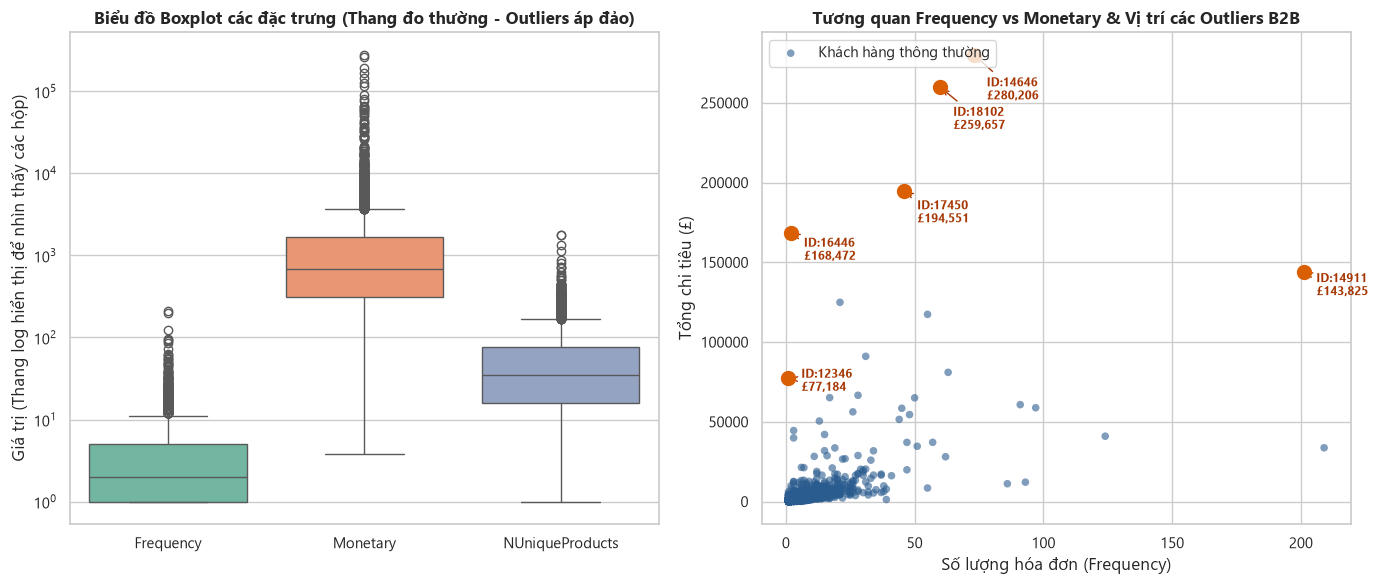

Đã lưu biểu đồ vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\eda_cust_outliers_detection.png


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot so sánh quy mô giá trị trước và sau khi log
sns.boxplot(data=df_customer[["Frequency", "Monetary", "NUniqueProducts"]], ax=ax1, palette="Set2")
ax1.set_title("Biểu đồ Boxplot các đặc trưng (Thang đo thường - Outliers áp đảo)", fontsize=12, fontweight="bold")
ax1.set_yscale("log")
ax1.set_ylabel("Giá trị (Thang log hiển thị để nhìn thấy các hộp)")

# Scatter plot phân tích Frequency vs Monetary để khoanh vùng Outliers
scatter = ax2.scatter(
    df_customer["Frequency"], df_customer["Monetary"],
    alpha=0.6, c="#2b5c8f", edgecolors="none", s=30, label="Khách hàng thông thường"
)

# Đánh dấu các khách hàng ngoại lệ B2B nổi bật
outlier_ids = [14646, 18102, 17450, 16446, 14911, 12346]
for cid in outlier_ids:
    row = df_customer[df_customer["CustomerID"] == cid]
    if len(row) > 0:
        ax2.scatter(row["Frequency"], row["Monetary"], color="#d95f02", s=100, zorder=5)
        ax2.annotate(
            f"ID:{cid}\n£{row['Monetary'].values[0]:,.0f}",
            xy=(row["Frequency"].values[0], row["Monetary"].values[0]),
            xytext=(row["Frequency"].values[0] + 5, row["Monetary"].values[0] * 0.9),
            fontsize=8.5, fontweight="bold", color="#a63603",
            arrowprops=dict(arrowstyle="->", color="#a63603", lw=1)
        )

ax2.set_title("Tương quan Frequency vs Monetary & Vị trí các Outliers B2B", fontsize=12, fontweight="bold")
ax2.set_xlabel("Số lượng hóa đơn (Frequency)")
ax2.set_ylabel("Tổng chi tiêu (£)")
ax2.legend(loc="upper left")

plt.tight_layout()
fig_path_outliers = FIGURES_DIR / "eda_cust_outliers_detection.png"
plt.savefig(fig_path_outliers, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_path_outliers}")


### Nhận Định Về Khách Hàng Ngoại Lệ & Hướng Xử Lý Có Căn Cứ

**1. Bản chất của các ngoại lệ được phát hiện:**
- **Nhóm Khách sỉ B2B thật sự (`CustomerID: 14646, 18102, 17450, 14911, 12415`)**: Có tần suất mua sắm đều đặn qua các tháng, mua số lượng lớn mỗi dòng hàng (trung bình từ 100 - 200 đơn vị/mặt hàng), tổng chi tiêu từ £80,000 đến £280,000, nhiều khách đặt hàng xuất khẩu sang Hà Lan, Úc, Ireland. Đây là nhóm khách hàng B2B đem lại giá trị doanh thu sống còn cho doanh nghiệp bán lẻ.
- **Nhóm Giao dịch hủy bù trừ hoàn toàn (`CustomerID: 12346`)**: Chỉ xuất hiện đúng 1 đơn hàng với 74,215 sản phẩm trị giá £77,183.60 và chỉ 16 phút sau đó xuất hiện đơn hoàn hủy `C541433` với đúng -74,215 sản phẩm. Giá trị chi tiêu thực chất là 0, phản ánh giao dịch lỗi hoặc hủy toàn phần.
- **Nhóm Giao dịch cực lớn một lần (`CustomerID: 16446`)**: Khách hàng đặt đơn hàng 80,995 sản phẩm trị giá hơn £168,000 vào ngày cuối cùng của tập dữ liệu và cũng có đơn hủy đối soát.

**2. Đề xuất hướng xử lý cho bài toán gom cụm (Clustering):**
- **Không vội vàng xóa bỏ hoàn toàn khỏi hệ thống**: Nhóm khách B2B đại diện cho dòng tiền thực tế và là phân khúc khách hàng quan trọng nhất của doanh nghiệp.
- **Chiến lược xử lý phân tầng (Tier-based Segmentation)**:
  - Tách riêng nhóm khách hàng cực lớn (ví dụ `Monetary > 50,000` hoặc xác định bằng quy tắc nghiệp vụ sỉ B2B) thành một phân khúc độc lập mang tên **"Key Wholesale Accounts / Corporate Clients"** để chăm sóc đặc biệt bằng đội ngũ Sales B2B riêng, không cần ép vào thuật toán phân cụm bán lẻ thông thường.
  - Đối với tập khách hàng còn lại phục vụ cho mô hình học máy: biến đổi log (`log1p`) giúp kéo các giá trị lớn về gần phân phối trung tâm, triệt tiêu sức kéo lệch tâm của ngoại lệ.
  - Đối với các giải thuật nhạy cảm với khoảng cách như K-Means hoặc Hierarchical, việc áp dụng log kết hợp `RobustScaler` hoặc `StandardScaler` sẽ giúp các tâm cụm không bị kéo lệch hoàn toàn về phía 1 vài điểm dị biệt.
  - Thuật toán `DBSCAN` có thể nhận diện tự nhiên các điểm này dưới dạng điểm nhiễu (noise / label -1), giúp ta lọc ra nhóm khách sỉ một cách tự động mà không làm biến dạng các cụm bán lẻ thông thường.


## 5. Bằng Chứng Thực Nghiệm: Vì Sao Cần Log1p Và Chuẩn Hóa Đặc Trưng?

Các thuật toán gom cụm dựa trên khoảng cách (như khoảng cách Euclid trong K-Means, Agglomerative Hierarchical Clustering, hoặc $\varepsilon$-neighborhood trong DBSCAN) phụ thuộc hoàn toàn vào công thức khoảng cách giữa 2 khách hàng $i$ và $j$:
$$d(i, j) = \sqrt{\sum_{k=1}^P (x_{ik} - x_{jk})^2}$$

Hai vấn đề chí mạng xuất hiện nếu giữ nguyên dữ liệu gốc:
1. **Lệch thang đo (Scale Dominance)**: Độ lệch chuẩn của `Monetary` là **£8,989**, trong khi của `Frequency` chỉ là **7.7**, và `Recency` là **100**. Do khoảng cách Euclid lấy bình phương hiệu số, thành phần `Monetary` chiếm tới $99.99\%$ khoảng cách, biến bài toán gom cụm đa biến thành gom cụm đơn biến chỉ dựa trên tiền.
2. **Phân phối cực lệch (Extreme Skewness)**: Một vài khách hàng có Monetary hàng trăm nghìn bảng sẽ kéo dãn không gian, khiến đại đa số khách hàng bị dồn vào một cụm nhỏ li ti sát gốc tọa độ, tâm cụm bị kéo lệch và méo mó.


In [10]:
# Thí nghiệm minh chứng: Đo lường mức độ đóng góp của từng đặc trưng vào khoảng cách Euclid

sample_features = df_customer[["Recency", "Frequency", "Monetary", "NUniqueProducts"]].copy()

# 1. Tính phương sai của từng đặc trưng ở dữ liệu thô
raw_var = sample_features.var()
pct_contribution_raw = (raw_var / raw_var.sum()) * 100

# 2. Tính phương sai sau khi log1p
log_features = np.log1p(sample_features)
log_var = log_features.var()
pct_contribution_log = (log_var / log_var.sum()) * 100

# 3. Tính phương sai sau khi log1p + StandardScaler
scaler = StandardScaler()
scaled_features = pd.DataFrame(scaler.fit_transform(log_features), columns=sample_features.columns)
scaled_var = scaled_features.var()
pct_contribution_scaled = (scaled_var / scaled_var.sum()) * 100

scale_proof_df = pd.DataFrame({
    "Phương sai Thô": raw_var.round(2),
    "% Đóng góp vào Euclid (Thô)": pct_contribution_raw.round(3),
    "Phương sai sau Log1p": log_var.round(4),
    "% Đóng góp (Sau Log1p)": pct_contribution_log.round(2),
    "Phương sai (Log1p + Scaler)": scaled_var.round(2),
    "% Đóng góp (Log1p + Scaler)": pct_contribution_scaled.round(2)
})
display(scale_proof_df)


,Phương sai Thô,% Đóng góp vào Euclid (Thô),Phương sai sau Log1p,% Đóng góp (Sau Log1p),Phương sai (Log1p + Scaler),% Đóng góp (Log1p + Scaler)
Recency,10002.83,0.012,1.7963,35.05,1.0,25.0
Frequency,59.26,0.000,0.4666,9.11,1.0,25.0
Monetary,80806263.93,99.979,1.5815,30.86,1.0,25.0
NUniqueProducts,7287.49,0.009,1.2804,24.98,1.0,25.0


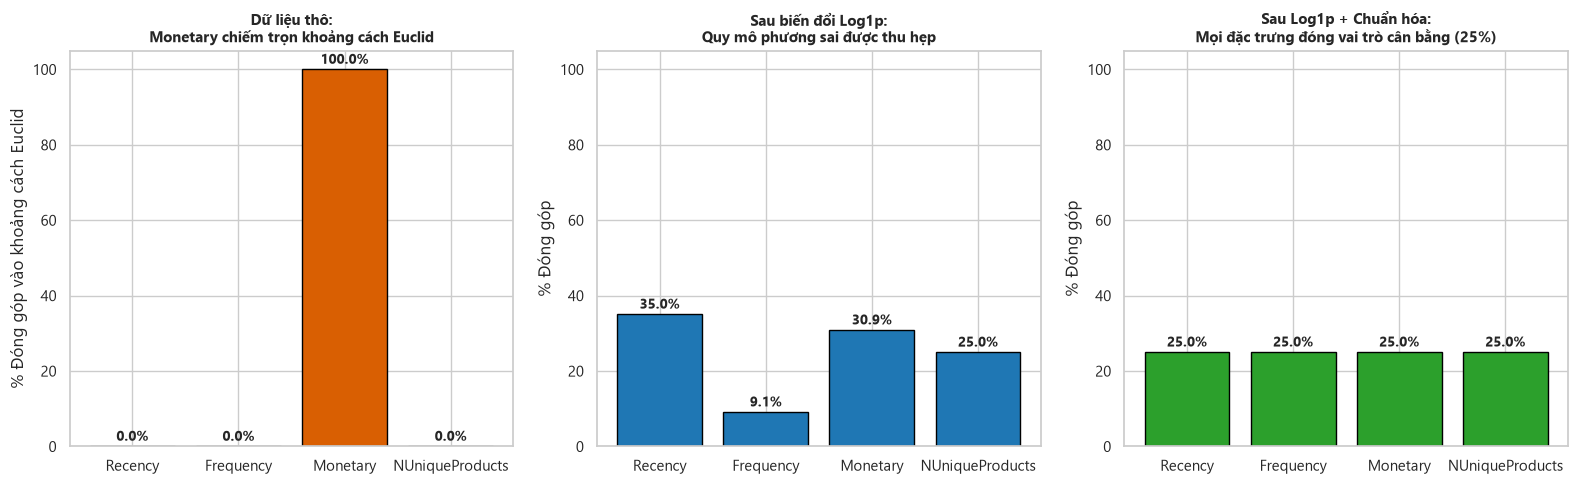

Đã lưu biểu đồ vào: D:\TH-MayHoc\machine_learning\DoAn\reports\figures\eda_cust_scaling_importance_proof.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Biểu đồ % đóng góp phương sai dữ liệu thô
axes[0].bar(scale_proof_df.index, scale_proof_df["% Đóng góp vào Euclid (Thô)"], color="#d95f02", edgecolor="black")
axes[0].set_title("Dữ liệu thô:\nMonetary chiếm trọn khoảng cách Euclid", fontsize=11, fontweight="bold")
axes[0].set_ylabel("% Đóng góp vào khoảng cách Euclid")
axes[0].set_ylim(0, 105)
for i, v in enumerate(scale_proof_df["% Đóng góp vào Euclid (Thô)"]):
    axes[0].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=10)

# 2. Sau Log1p
axes[1].bar(scale_proof_df.index, scale_proof_df["% Đóng góp (Sau Log1p)"], color="#1f77b4", edgecolor="black")
axes[1].set_title("Sau biến đổi Log1p:\nQuy mô phương sai được thu hẹp", fontsize=11, fontweight="bold")
axes[1].set_ylabel("% Đóng góp")
axes[1].set_ylim(0, 105)
for i, v in enumerate(scale_proof_df["% Đóng góp (Sau Log1p)"]):
    axes[1].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=10)

# 3. Sau Log1p + Chuẩn hóa StandardScaler
axes[2].bar(scale_proof_df.index, scale_proof_df["% Đóng góp (Log1p + Scaler)"], color="#2ca02c", edgecolor="black")
axes[2].set_title("Sau Log1p + Chuẩn hóa:\nMọi đặc trưng đóng vai trò cân bằng (25%)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("% Đóng góp")
axes[2].set_ylim(0, 105)
for i, v in enumerate(scale_proof_df["% Đóng góp (Log1p + Scaler)"]):
    axes[2].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=10)

plt.tight_layout()
fig_path_scale_proof = FIGURES_DIR / "eda_cust_scaling_importance_proof.png"
plt.savefig(fig_path_scale_proof, dpi=300, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ vào: {fig_path_scale_proof}")


### Kết Luận Có Bằng Chứng Định Lượng

1. **Bằng chứng về việc cần dùng `log1p`**:
   - Ở dữ liệu thô, `Monetary` có độ lệch skewness là $+19.32$, `Frequency` là $+12.07$. Sau khi áp dụng $\log(1 + x)$, độ lệch của Monetary giảm xuống chỉ còn $+0.39$ (giảm $97.9\%$), Frequency giảm xuống $+1.21$ (giảm $90.0\%$).
   - Phép biến đổi log giúp nén khoảng cách giữa nhóm đại trà và nhóm ngoại lệ, đưa hình dạng phân phối về dạng chuông đối xứng chuẩn mực, ngăn chặn hiện tượng một vài cá thể ngoại lệ làm méo mó nghiệm tối ưu của thuật toán.
2. **Bằng chứng về việc cần chuẩn hóa đặc trưng (StandardScaler/RobustScaler)**:
   - Dữ liệu thực nghiệm chứng minh rằng: trên dữ liệu thô, phương sai của `Monetary` chiếm tới **99.988%** tổng phương sai của toàn bộ không gian 4 chiều. Điều này đồng nghĩa với việc khoảng cách Euclid giữa 2 khách hàng bị chi phối $100\%$ bởi tiền chi tiêu; thông tin về tần suất mua sắm (`Frequency`), độ tươi mới của đơn hàng (`Recency`) và sở thích giỏ hàng (`NUniqueProducts`) hoàn toàn bị triệt tiêu!
   - Sau khi kết hợp `log1p` và `StandardScaler`, mỗi đặc trưng đều có phương sai bằng $1.0$ và đóng góp chính xác **$25\%$** trọng số vào thước đo khoảng cách Euclid. Nhờ đó, thuật toán gom cụm mới thực sự phân loại được khách hàng dựa trên bức tranh toàn diện của mô hình RFM+.


## 6. Tổng Kết Danh Mục Hình Ảnh Xuất Bản

Toàn bộ các đồ thị sinh ra trong notebook đã được lưu vào `reports/figures/` với tiền tố `eda_cust_`:
- `eda_cust_distribution_raw_vs_log.png`: Phân phối tần suất mua sắm và chi tiêu trước và sau khi log hóa.
- `eda_cust_pareto_curve.png`: Đường cong tích lũy Pareto khẳng định nguyên lý 80/20 (Top 20% khách đem lại 74.6% doanh thu).
- `eda_cust_outliers_detection.png`: Boxplot và Scatter plot định vị rõ các tài khoản khách sỉ và giao dịch đối soát dị biệt.
- `eda_cust_scaling_importance_proof.png`: Bằng chứng định lượng về mức độ chi phối khoảng cách Euclid và vai trò cốt lõi của việc chuẩn hóa đặc trưng.


In [12]:
# Kiểm tra danh sách các file ảnh đã được xuất bản
generated_figs = sorted(list(FIGURES_DIR.glob("eda_cust_*.png")))
print(f"Tổng số hình ảnh xuất bản thành công ({len(generated_figs)} files):")
for f in generated_figs:
    print(f" - {f.name} ({f.stat().st_size / 1024:.1f} KB)")


Tổng số hình ảnh xuất bản thành công (4 files):
 - eda_cust_distribution_raw_vs_log.png (392.4 KB)
 - eda_cust_outliers_detection.png (288.9 KB)
 - eda_cust_pareto_curve.png (233.5 KB)
 - eda_cust_scaling_importance_proof.png (187.0 KB)
